# Layer-25 causal replay: final results (#218)

**Solver A1 → Critic → Solver A2.** We turn off the TopK SAE features that our layer-25 adoption probe selected, *inside the live Solver*, and measure whether it still adopts the Critic's answer.

Run `results/causal_topk_mixed_layer25/20261103T024624099539Z` (#216, PR #217) · Claude labels · every number is read from the committed files.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RUN = ROOT / "results/causal_topk_mixed_layer25/20261103T024624099539Z"
RES = RUN / "distributed/merged_exclude_empty6"
PROBE = ROOT / "results/probe_mixed_final_001_layer25/20261102T185349607791Z"
SAE = ROOT / "results/sae/musique/runs/layer_25/20261102T182749413400Z-150e78c341c6"
OUT = ROOT / "reports/figures/causal_topk_layer25"
(OUT / "tables").mkdir(parents=True, exist_ok=True)

INPUTS = [RES / n for n in ("targeted_vs_random.csv", "causal_table.csv", "diagnostics.csv", "changed_answers.csv",
                            "control_match.csv", "replay_config.json", "replay_check.json", "derived_from.json",
                            "claude_labeled/summary.json", "episodes.csv")]
INPUTS += [PROBE / "feature_selection_summary.json", PROBE / "top_features_TopK SAE.csv", SAE / "config.json"]
sha = lambda p: hashlib.sha256(p.read_bytes()).hexdigest()
BEFORE = {str(p.relative_to(ROOT)): sha(p) for p in INPUTS}

tvr = pd.read_csv(RES / "targeted_vs_random.csv")
table = pd.read_csv(RES / "causal_table.csv")
diag = pd.read_csv(RES / "diagnostics.csv")
changed = pd.read_csv(RES / "changed_answers.csv")
match = pd.read_csv(RES / "control_match.csv")
meta = json.loads((RES / "replay_config.json").read_text())
cfg = meta["config"]
labels = json.loads((RES / "claude_labeled/summary.json").read_text())
check = json.loads((RES / "replay_check.json").read_text())
derived = json.loads((RES / "derived_from.json").read_text())
probe = json.loads((PROBE / "feature_selection_summary.json").read_text())
sae_cfg = json.loads((SAE / "config.json").read_text())

# Cohort counts from the source Claude labeling run (results/claude_validation/mixed_final_001/intervention/
# summary.json and binary_labels.csv on the coordinator; not in the repo). Checked 2026-11-03.
UPSTREAM = {"labeled": 10105, "adoption": 1814, "retention": 1704}

GROUPS = {"All 10 features": "TopK SAE · error-preserving",
          "f1666 alone": "TopK SAE · f1666 · error-preserving",
          "Other 9 (without f1666)": "TopK SAE · without_1666 · error-preserving"}
ARMS = {"ablation": ("Turn off", "ablation"),
        "norm_-0.01": ("Turn down 1%", "suppress (|Δ| ≤ 0.01·|x|)"),
        "norm_-0.02": ("Turn down 2%", "suppress (|Δ| ≤ 0.02·|x|)")}


def one(df, **where):
    """The single row matching every column=value; anything else is an error, never a silent pick."""
    hit = df
    for col, val in where.items():
        hit = hit[hit[col] == val]
    if len(hit) != 1:
        raise ValueError(f"expected one row for {where}, got {len(hit)}")
    return hit.iloc[0]


def ci(text):
    lo, hi = (float(v) for v in str(text).strip("[]").split(","))
    return lo, hi


def fmt_p(p):
    return f"{p:.4f}" if p < 0.001 else f"{p:.3f}" if p < 0.01 else f"{p:.2f}"


# reference palette (dataviz skill), light surface; validated: blue/aqua/orange pass all-pairs CVD checks
SURF, INK, INK2, MUTED, GRID, AXIS, WASH = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#f0efec"
TARGETED, F1666, RANDOM = "#2a78d6", "#1baf7a", "#eb6834"
plt.rcParams.update({
    "font.family": ["Arial", "DejaVu Sans"], "font.size": 11, "svg.fonttype": "none", "svg.hashsalt": "issue218",
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "xtick.labelcolor": MUTED, "ytick.color": INK2,
    "ytick.labelcolor": INK, "figure.dpi": 110,
})


def style(ax, grid_axis="x"):
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.tick_params(length=0)
    ax.grid(axis=grid_axis, color=GRID, linewidth=1)
    ax.set_axisbelow(True)


def heading(ax, title, subtitle):
    where = ("figure fraction", "axes fraction")
    ax.annotate(title, (0.02, 1), xycoords=where, xytext=(0, 34), textcoords="offset points",
                ha="left", va="bottom", fontsize=14, fontweight="bold", color=INK)
    ax.annotate(subtitle, (0.02, 1), xycoords=where, xytext=(0, 14), textcoords="offset points",
                ha="left", va="bottom", fontsize=10, color=INK2)


def save(fig, name):
    fig.savefig(OUT / f"{name}.svg", bbox_inches="tight", pad_inches=0.25, metadata={"Date": None})
    fig.savefig(OUT / f"{name}.pdf", bbox_inches="tight", pad_inches=0.25, metadata={"CreationDate": None})
    plt.show()


def show(df, name):
    df.to_csv(OUT / "tables" / f"{name}.csv", index=False)
    display(df.style.hide(axis="index"))


n_eps = labels["n_analysis_episodes"]
assert labels["status"] == "complete_with_exclusions" and n_eps == cfg["limit"] - len(derived["empty_answer_questions"])
print(f"{n_eps} analysed episodes · {len(meta['conditions'])} conditions each · inputs hashed")

494 analysed episodes · 916 conditions each · inputs hashed


## 1 · Design and data quality

In [2]:
eligible = UPSTREAM["adoption"] + UPSTREAM["retention"]
assert check["passed"] and check["mismatch_counts"] == {"exact_match": check["n_episodes"]}
design = pd.DataFrame([
    ("Intervention episodes labeled by Claude", f"{UPSTREAM['labeled']:,}", "source labeling run"),
    ("Eligible (Adoption + Retention)", f"{UPSTREAM['adoption']:,} + {UPSTREAM['retention']:,} = {eligible:,}", "source labeling run"),
    ("Replayed: first N of the seed-42 order", f"{cfg['limit']}", "replay_config.json"),
    ("Plain replay reproduces the stored answer", f"{check['mismatch_counts']['exact_match']} / {check['n_episodes']}", "replay_check.json"),
    ("Excluded: empty answer under targeted ablation", f"{len(derived['empty_answer_questions'])}", "derived_from.json"),
    ("Analysed", f"{n_eps}", "claude_labeled/summary.json"),
    ("Conditions per episode", f"{len(meta['conditions'])}", "replay_config.json"),
    ("Random draws per random arm", f"{cfg['n_random_draws']} (contribution-matched)", "replay_config.json"),
    ("Generations", f"{labels['n_generations']:,}", "claude_labeled/summary.json"),
    ("Where the edit is applied", "layer 25 residual stream, final prompt token of the revise prompt", "causal_replay_summary.json"),
    ("SAE input normalization", f"÷ one training RMS ({sae_cfg['activation_rms_scale']:.1f}), restored on decode", "SAE config.json"),
    ("Edit size reported below", "‖Δx‖ / ‖x‖ in the model's own units (not the SAE's scaled units)", "diagnostics.csv"),
], columns=["", "Value", "Source"])
show(design, "1_design")

,Value,Source
Intervention episodes labeled by Claude,"10,105",source labeling run
Eligible (Adoption + Retention),"1,814 + 1,704 = 3,518",source labeling run
Replayed: first N of the seed-42 order,500,replay_config.json
Plain replay reproduces the stored answer,500 / 500,replay_check.json
Excluded: empty answer under targeted ablation,6,derived_from.json
Analysed,494,claude_labeled/summary.json
Conditions per episode,916,replay_config.json
Random draws per random arm,100 (contribution-matched),replay_config.json
Generations,"458,000",claude_labeled/summary.json
Where the edit is applied,"layer 25 residual stream, final prompt token of the revise prompt",causal_replay_summary.json


## 2 · What the layer-25 probes found (input to the intervention)

In [3]:
rep = pd.DataFrame([{
    "Representation": name,
    "Probe balanced accuracy (validation)": f"{t['probe']['balanced_accuracy_eval']:.3f}",
    "Variance explained": "—" if name.startswith("Raw") else f"{t['variance_explained_eval']:.3f}",
    "Mean active features": "—" if t.get("mean_active_features_eval") is None else f"{t['mean_active_features_eval']:.0f}",
} for name, t in probe["saes"].items()])
show(rep, "2_probe_by_representation")

Representation,Probe balanced accuracy (validation),Variance explained,Mean active features
Raw activations,0.843,—,—
L1 SAE,0.773,0.883,47
TopK SAE,0.753,0.914,128
Pretrained SAE,0.706,0.238,112


## 3 · The 10 features we turned off

In [4]:
top = pd.read_csv(PROBE / "top_features_TopK SAE.csv")
m = (match[match.Set == "targeted"].groupby("targeted")
     .agg(freq=("targeted_frequency", "first"), contrib=("targeted_contribution", "first"),
          ctrl=("control_contribution", "median"), distinct=("control", "nunique")))
assert len(m) == 10 and set(m.index) <= set(top.feature)
feat = top.set_index("feature").loc[m.index].join(m).sort_values("contrib", ascending=False)
features = pd.DataFrame({
    "Feature": [f"f{f}" for f in feat.index],
    "Probe rank": feat["rank"].astype(int),
    "Fires on (% of rows)": (100 * feat.freq).round(0).astype(int),
    "Contribution": feat.contrib.round(0).astype(int),
    "Median contribution of its 100 controls": feat.ctrl.round(0).astype(int),
    "Distinct controls": feat.distinct,
})
show(features, "3_targeted_features")
big = feat.loc[1666]
print(f"f1666 fires on {big.freq:.0%} of rows; its contribution is {big.contrib / big.ctrl:.0f}× its controls' median "
      f"({int(big.distinct)} distinct controls). The next largest feature is {feat.contrib.iloc[1] / feat.contrib.iloc[0]:.1%} of its size.")

Feature,Probe rank,Fires on (% of rows),Contribution,Median contribution of its 100 controls,Distinct controls
f1666,7,100,27858,495,27
f744,11,89,435,412,40
f10943,8,69,384,218,35
f2828,3,23,379,162,41
f6854,14,91,360,400,39
f12274,4,83,325,262,45
f2737,16,70,224,215,36
f5904,27,40,206,192,42
f189,19,70,198,206,35
f4784,20,38,120,147,44


f1666 fires on 100% of rows; its contribution is 56× its controls' median (27 distinct controls). The next largest feature is 1.6% of its size.


## 4 · Does turning the features off change the Solver's adoption?

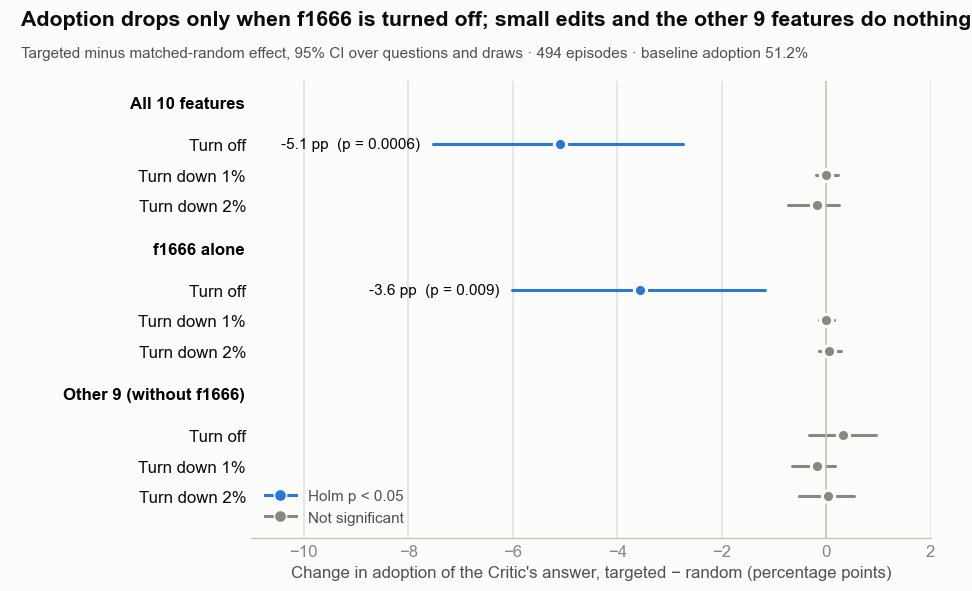

Features,Edit,Edit size targeted (%),Edit size random (%),Adoption targeted (%),Adoption random (%),Targeted − random (pp),95% CI,p (Holm)
All 10 features,Turn off,86.070000,3.310000,45.950000,51.040000,-5.090000,"[-7.5, -2.7]",0.0006
All 10 features,Turn down 1%,1.000000,1.000000,51.210000,51.210000,0.010000,"[-0.2, 0.2]",1.00
All 10 features,Turn down 2%,2.000000,1.930000,51.010000,51.190000,-0.180000,"[-0.7, 0.2]",1.00
f1666 alone,Turn off,85.370000,1.280000,47.570000,51.140000,-3.570000,"[-6.0, -1.2]",0.009
f1666 alone,Turn down 1%,1.000000,0.780000,51.210000,51.210000,0.000000,"[-0.1, 0.1]",1.00
f1666 alone,Turn down 2%,2.000000,1.140000,51.210000,51.160000,0.050000,"[-0.1, 0.3]",1.00
Other 9 (without f1666),Turn off,2.680000,2.790000,51.420000,51.100000,0.320000,"[-0.3, 1.0]",0.34
Other 9 (without f1666),Turn down 1%,1.000000,1.000000,51.010000,51.180000,-0.170000,"[-0.7, 0.2]",1.00
Other 9 (without f1666),Turn down 2%,1.860000,1.850000,51.210000,51.180000,0.040000,"[-0.5, 0.5]",1.00


In [5]:
rows = []
for group, exp in GROUPS.items():
    for arm, (edit, cond) in ARMS.items():
        t = one(tvr, Experiment=exp, Arm=arm, Control="matched features", Rows="all")
        lo, hi = ci(t["95% CI (questions + draws)"])
        edit_size = lambda side: 100 * float(one(diag, Experiment=exp, Condition=f"{side} {cond}")["Mean edit norm (rel. to |x|)"])
        rows.append({"Features": group, "Edit": edit, "Targeted − random (pp)": float(t["Targeted − random (pp)"]),
                     "lo": lo, "hi": hi, "p (Holm)": float(t["p-value (Holm)"]),
                     "Adoption targeted (%)": float(one(table, Experiment=exp, Condition=f"Targeted {cond}")["Acceptance Rate (%)"]),
                     "Adoption random (%)": float(one(table, Experiment=exp, Condition=f"Random {cond}")["Acceptance Rate (%)"]),
                     "Edit size targeted (%)": edit_size("Targeted"), "Edit size random (%)": edit_size("Random")})
res = pd.DataFrame(rows)
baseline = float(one(table, Experiment="Baseline", Condition="No SAE (replayed A2)")["Acceptance Rate (%)"])

fig, ax = plt.subplots(figsize=(9.5, 5.4))
fig.subplots_adjust(left=0.25)
ypos, ylabels, y = [], [], 0
for group in GROUPS:
    ax.text(-0.01, y - 0.15, group, transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=11, fontweight="bold")
    y += 0.9
    for _, r in res[res.Features == group].iterrows():
        d, p = r["Targeted − random (pp)"], r["p (Holm)"]
        color = TARGETED if p < 0.05 else MUTED
        ax.plot([r.lo, r.hi], [y, y], color=color, linewidth=2, solid_capstyle="round", zorder=2)
        ax.scatter([d], [y], s=64, color=color, edgecolors=SURF, linewidths=2, zorder=3)
        if p < 0.05:
            ax.text(r.lo - 0.25, y, f"{d:+.1f} pp  (p = {fmt_p(p)})", ha="right", va="center", fontsize=10)
        ypos.append(y); ylabels.append(r.Edit); y += 0.8
    y += 0.5
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(ypos, ylabels)
ax.set_ylim(y - 0.2, -0.75)
ax.set_xlim(-11, 2)
ax.set_xlabel("Change in adoption of the Critic's answer, targeted − random (percentage points)")
style(ax)
ax.legend(handles=[plt.Line2D([], [], marker="o", linewidth=2, markersize=8, color=c, markeredgecolor=SURF, label=l)
                   for c, l in ((TARGETED, "Holm p < 0.05"), (MUTED, "Not significant"))],
          loc="lower left", frameon=False, fontsize=10, labelcolor=INK2)
heading(ax, "Adoption drops only when f1666 is turned off; small edits and the other 9 features do nothing",
        f"Targeted minus matched-random effect, 95% CI over questions and draws · {n_eps} episodes · baseline adoption {baseline:.1f}%")
save(fig, "1_effect_forest")

summary = res.assign(**{"95% CI": [f"[{a:.1f}, {b:.1f}]" for a, b in zip(res.lo, res.hi)],
                         "p (Holm)": res["p (Holm)"].map(fmt_p)}).drop(columns=["lo", "hi"])
show(summary.round(2)[["Features", "Edit", "Edit size targeted (%)", "Edit size random (%)", "Adoption targeted (%)",
                        "Adoption random (%)", "Targeted − random (pp)", "95% CI", "p (Holm)"]], "4_effects")

## 5 · Is the effect explained by edit size?

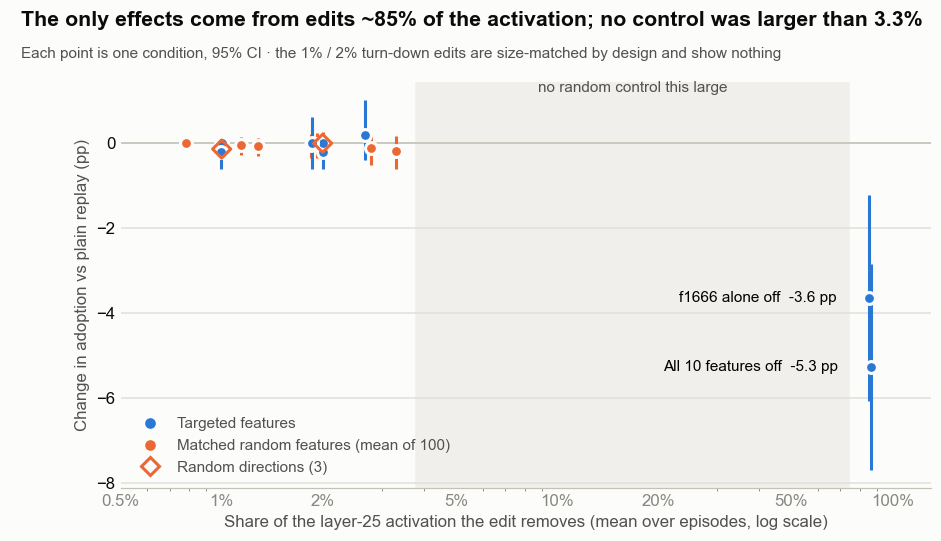

In [6]:
pts = []
for group, exp in GROUPS.items():
    for arm, (edit, cond) in ARMS.items():
        for side in ("Targeted", "Random"):
            r = one(table, Experiment=exp, Condition=f"{side} {cond}")
            lo, hi = ci(r["95% CI for Δ"])
            size = 100 * float(one(diag, Experiment=exp, Condition=f"{side} {cond}")["Mean edit norm (rel. to |x|)"])
            pts.append(dict(group=group, edit=edit, kind=side, size=size, delta=float(r["Δ vs. SAE Control (pp)"]), lo=lo, hi=hi))
for cond in ("Random suppress (|Δ| = 0.01·|x|)", "Random suppress (|Δ| = 0.02·|x|)"):
    r = one(table, Experiment="Random direction · error-preserving", Condition=cond)
    lo, hi = ci(r["95% CI for Δ"])
    size = 100 * float(one(diag, Experiment="Random direction · error-preserving", Condition=cond)["Mean edit norm (rel. to |x|)"])
    pts.append(dict(group="Random direction", edit=cond, kind="Random direction", size=size,
                    delta=float(r["Δ vs. SAE Control (pp)"]), lo=lo, hi=hi))
pts = pd.DataFrame(pts)
largest_control = pts[pts.kind != "Targeted"]["size"].max()
big = pts[(pts.kind == "Targeted") & (pts["size"] > 10)]

fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.axvspan(largest_control * 1.15, big["size"].min() / 1.15, color=WASH, zorder=0)
ax.text((largest_control * big["size"].min()) ** 0.5, 1.2, "no random control this large", ha="center", fontsize=10, color=INK2)
ax.axhline(0, color=AXIS, linewidth=1)
for kind, color, marker in (("Random", RANDOM, "o"), ("Targeted", TARGETED, "o"), ("Random direction", RANDOM, "D")):
    p = pts[pts.kind == kind]
    ax.vlines(p["size"], p.lo, p.hi, color=color, linewidth=2, zorder=2)
    if kind == "Random direction":   # drawn last and hollow: they sit at exactly 1% and 2%, on top of targeted points
        ax.scatter(p["size"], p.delta, s=70, marker=marker, facecolors="none", edgecolors=color, linewidths=2, zorder=4)
    else:
        ax.scatter(p["size"], p.delta, s=60, color=color, marker=marker, edgecolors=SURF, linewidths=2, zorder=3)
for _, r in big.iterrows():
    ax.text(r["size"] / 1.25, r.delta, f"{r.group} off  {r.delta:+.1f} pp", ha="right", va="center", fontsize=10)
ax.set_xscale("log")
ax.set_xlim(0.5, 130)
ax.set_xticks([0.5, 1, 2, 5, 10, 20, 50, 100], ["0.5%", "1%", "2%", "5%", "10%", "20%", "50%", "100%"])
ax.set_xlabel("Share of the layer-25 activation the edit removes (mean over episodes, log scale)")
ax.set_ylabel("Change in adoption vs plain replay (pp)")
style(ax, grid_axis="y")
ax.legend(handles=[plt.Line2D([], [], marker=mk, linestyle="", markersize=8, color=c, markeredgecolor=SURF, label=l)
                   for c, mk, l in ((TARGETED, "o", "Targeted features"), (RANDOM, "o", "Matched random features (mean of 100)"))]
          + [plt.Line2D([], [], marker="D", linestyle="", markersize=8, markerfacecolor="none", markeredgecolor=RANDOM,
                        markeredgewidth=2, label="Random directions (3)")],
          loc="lower left", frameon=False, fontsize=10, labelcolor=INK2)
heading(ax, f"The only effects come from edits ~{big['size'].min():.0f}% of the activation; no control was larger than {largest_control:.1f}%",
        "Each point is one condition, 95% CI · the 1% / 2% turn-down edits are size-matched by design and show nothing")
save(fig, "2_effect_vs_edit_size")

## 6 · Did the decision switch, or did the answer break?

Edit,Generations,Answer changed (%),"Reworded, same label (%)",Adoption→Retention,Retention→Adoption,Became Out,Episodes with an Adoption↔Retention flip
All 10 features: turn off,494,18.830000,7.490000,22,7,26,29
f1666 alone: turn off,494,18.620000,7.090000,19,11,26,30
Other 9 (without f1666): turn off,494,1.010000,0.400000,1,2,0,3
Random features: turn off (all 3 arms),148200,1.150000,0.510000,528,353,59,44


Features,Total (pp),Part,Effect (pp),95% CI,p,p (Holm)
All 10 features,-5.090000,Switch to Retention,-2.870000,"[-4.9, -0.9]",0.004,0.02
All 10 features,-5.090000,Broken answer (Out),-2.220000,"[-3.6, -1.0]",0.001,0.007
f1666 alone,-3.570000,Switch to Retention,-1.550000,"[-3.7, 0.6]",0.16,0.48
f1666 alone,-3.570000,Broken answer (Out),-2.020000,"[-3.4, -1.0]",0.002,0.008
Other 9 (without f1666),0.320000,Switch to Retention,0.320000,"[-0.3, 1.0]",0.36,0.71
Other 9 (without f1666),0.320000,Broken answer (Out),0.000000,"[0.0, 0.0]",1.00,1.00


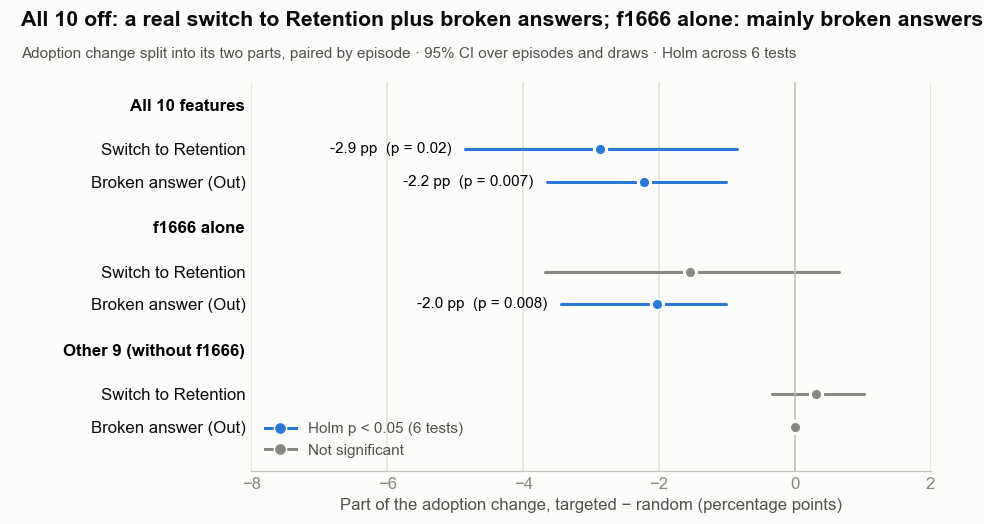

In [7]:
# Every adoption change is a per-episode transition from the plain replay's label. Random draws of one episode are
# not independent observations, so every test here is paired by episode (targeted vs that episode's random draws),
# with a bootstrap over episodes and draws and a sign-flip permutation over episodes, like the main analysis.
KINDS = {"A→R": ("adopted_critic", "retained_a1"), "R→A": ("retained_a1", "adopted_critic"),
         "A→Out": ("adopted_critic", "out"), "A→Agreement": ("adopted_critic", "unchanged_same_position")}
assert set(changed.solver_response_ctl) <= {"adopted_critic", "retained_a1"}
assert not changed.duplicated(["question_id", "experiment", "condition", "draw"]).any()
qids = [q for q in pd.read_csv(RES / "episodes.csv").question_id if q not in set(derived["empty_answer_questions"])]
assert len(qids) == n_eps
pos, DRAWS = {q: i for i, q in enumerate(qids)}, cfg["n_random_draws"]


def indicators(exp, cond, n_draws):
    """{kind: episodes x draws 0/1 matrix} of each transition (targeted conditions have one column)."""
    c = changed[(changed.experiment == exp) & (changed.condition == cond)]
    mats = {k: np.zeros((len(qids), n_draws)) for k in KINDS}
    for k, (a, b) in KINDS.items():
        hit = c[(c.solver_response_ctl == a) & (c.solver_response == b)]
        for q, d in zip(hit.question_id, hit.draw):
            mats[k][pos[q], 0 if n_draws == 1 else int(d)] = 1
    return mats


rng = np.random.default_rng(cfg["seed"])


def paired_effect(t, r):
    """Mean over episodes of t − (mean of r over draws), in pp, with a 95% CI over episodes and draws and a
    two-sided sign-flip permutation p over episodes."""
    diff = t - r.mean(axis=1)
    boot = []
    for _ in range(cfg["n_bootstrap"]):
        e, d = rng.integers(0, len(t), len(t)), rng.integers(0, r.shape[1], r.shape[1])
        boot.append((t[e] - r[e][:, d].mean(axis=1)).mean())
    flips = rng.choice([-1.0, 1.0], size=(cfg["n_permutations"], len(diff)))
    p = ((np.abs((flips * diff).mean(axis=1)) >= abs(diff.mean()) - 1e-12).sum() + 1) / (cfg["n_permutations"] + 1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return 100 * diff.mean(), 100 * lo, 100 * hi, p


def holm(ps):
    order, adj, running = np.argsort(ps), np.empty(len(ps)), 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (len(ps) - rank) * ps[i]))
        adj[i] = running
    return adj


# descriptive counts (no tests: pooled random draws are clustered by episode)
counts, parts = [], []
rand_flip_eps, rand_rows = set(), {k: 0 for k in ("Generations", "changed", "same", "A→R", "R→A", "Out")}
for group, exp in GROUPS.items():
    t, r = indicators(exp, "targeted_ablation", 1), indicators(exp, "random_ablation", DRAWS)
    for name, mats, n_gen, cond in (("t", t, n_eps, "targeted_ablation"), ("r", r, n_eps * DRAWS, "random_ablation")):
        c = changed[(changed.experiment == exp) & (changed.condition == cond)]
        row = {"Generations": n_gen, "changed": len(c), "same": int((c.solver_response_ctl == c.solver_response).sum()),
               "A→R": int(mats["A→R"].sum()), "R→A": int(mats["R→A"].sum()), "Out": int((c.solver_response == "out").sum())}
        flip_eps = set(np.flatnonzero((mats["A→R"] + mats["R→A"]).sum(axis=1)))
        if name == "t":
            counts.append({"Edit": f"{group}: turn off", **row, "Episodes with an Adoption↔Retention flip": len(flip_eps)})
        else:
            rand_flip_eps |= flip_eps
            rand_rows = {k: rand_rows[k] + row[k] for k in rand_rows}
    # adoption change targeted − random = switch to Retention + broken answers (+ a rare move to Agreement)
    comps = {"Switch to Retention": (t["R→A"][:, 0] - t["A→R"][:, 0], r["R→A"] - r["A→R"]),
             "Broken answer (Out)": (-t["A→Out"][:, 0], -r["A→Out"]),
             "Other (to Agreement)": (-t["A→Agreement"][:, 0], -r["A→Agreement"])}
    est = {k: paired_effect(*v) for k, v in comps.items()}
    total = float(one(tvr, Experiment=exp, Arm="ablation", Control="matched features", Rows="all")["Targeted − random (pp)"])
    assert abs(sum(v[0] for v in est.values()) - total) < 0.01, "the parts must add up to the headline effect"
    for k, (m, lo, hi, p) in est.items():
        if k != "Other (to Agreement)" or abs(m) >= 0.01:
            parts.append({"Features": group, "Part": k, "Effect (pp)": m, "lo": lo, "hi": hi, "p": p, "Total (pp)": total})
counts.append({"Edit": "Random features: turn off (all 3 arms)", **rand_rows,
               "Episodes with an Adoption↔Retention flip": len(rand_flip_eps)})
counts = pd.DataFrame(counts)
counts = pd.DataFrame({"Edit": counts.Edit, "Generations": counts.Generations,
                       "Answer changed (%)": (100 * counts.changed / counts.Generations).round(2),
                       "Reworded, same label (%)": (100 * counts.same / counts.Generations).round(2),
                       "Adoption→Retention": counts["A→R"], "Retention→Adoption": counts["R→A"], "Became Out": counts.Out,
                       "Episodes with an Adoption↔Retention flip": counts["Episodes with an Adoption↔Retention flip"]})
show(counts, "6a_transition_counts")

parts = pd.DataFrame(parts)
parts["p (Holm)"] = holm(parts.p.to_numpy())
show(parts.assign(**{"Effect (pp)": parts["Effect (pp)"].round(2), "95% CI": [f"[{a:.1f}, {b:.1f}]" for a, b in zip(parts.lo, parts.hi)],
                     "p": parts.p.map(fmt_p), "p (Holm)": parts["p (Holm)"].map(fmt_p)})
     [["Features", "Total (pp)", "Part", "Effect (pp)", "95% CI", "p", "p (Holm)"]].round(2), "6b_adoption_change_parts")

# figure: the two parts of each adoption change
fig, ax = plt.subplots(figsize=(9.5, 4.6))
fig.subplots_adjust(left=0.25)
ypos, ylabels, y = [], [], 0
for group in GROUPS:
    ax.text(-0.01, y - 0.15, group, transform=ax.get_yaxis_transform(), ha="right", va="center", fontsize=11, fontweight="bold")
    y += 0.9
    for _, r in parts[(parts.Features == group) & (parts.Part != "Other (to Agreement)")].iterrows():
        color = TARGETED if r["p (Holm)"] < 0.05 else MUTED
        ax.plot([r.lo, r.hi], [y, y], color=color, linewidth=2, solid_capstyle="round", zorder=2)
        ax.scatter([r["Effect (pp)"]], [y], s=64, color=color, edgecolors=SURF, linewidths=2, zorder=3)
        if r["p (Holm)"] < 0.05:
            ax.text(r.lo - 0.2, y, f"{r['Effect (pp)']:+.1f} pp  (p = {fmt_p(r['p (Holm)'])})", ha="right", va="center", fontsize=10)
        ypos.append(y); ylabels.append(r.Part); y += 0.8
    y += 0.5
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(ypos, ylabels)
ax.set_ylim(y - 0.2, -0.75)
ax.set_xlim(-8, 2)
ax.set_xlabel("Part of the adoption change, targeted − random (percentage points)")
style(ax)
ax.legend(handles=[plt.Line2D([], [], marker="o", linewidth=2, markersize=8, color=c, markeredgecolor=SURF, label=l)
                   for c, l in ((TARGETED, f"Holm p < 0.05 ({len(parts)} tests)"), (MUTED, "Not significant"))],
          loc="lower left", frameon=False, fontsize=10, labelcolor=INK2)
P = parts.set_index(["Features", "Part"])
sw10, out10 = P.loc[("All 10 features", "Switch to Retention")], P.loc[("All 10 features", "Broken answer (Out)")]
sw1, out1 = P.loc[("f1666 alone", "Switch to Retention")], P.loc[("f1666 alone", "Broken answer (Out)")]
heading(ax, "All 10 off: a real switch to Retention plus broken answers; f1666 alone: mainly broken answers",
        f"Adoption change split into its two parts, paired by episode · 95% CI over episodes and draws · Holm across {len(parts)} tests")
save(fig, "3_answer_transitions")

## 7 · Bottom line

In [8]:
r = res.set_index(["Features", "Edit"])
all10, f1, other = (r.loc[(g, "Turn off")] for g in GROUPS)
print(f"""Shown
  • Turning off all 10 selected features lowers Critic adoption by {-all10['Targeted − random (pp)']:.1f} pp vs matched random features (Holm p = {fmt_p(all10['p (Holm)'])}):
    {sw10['Effect (pp)']:+.1f} pp is a switch to Retention (p = {fmt_p(sw10['p (Holm)'])}) and {out10['Effect (pp)']:+.1f} pp is broken (Out) answers (p = {fmt_p(out10['p (Holm)'])}).
  • f1666 alone: {f1['Targeted − random (pp)']:+.1f} pp (p = {fmt_p(f1['p (Holm)'])}), mainly broken answers ({out1['Effect (pp)']:+.1f} pp, p = {fmt_p(out1['p (Holm)'])});
    its switch to Retention ({sw1['Effect (pp)']:+.1f} pp, p = {fmt_p(sw1['p (Holm)'])}) is not significant.
  • The other 9 ({other['Targeted − random (pp)']:+.1f} pp, p = {fmt_p(other['p (Holm)'])}) and every size-matched 1–2% edit change nothing.
Not yet shown
  • That f1666 specifically drives adoption: it fires on every input and its removal is {f1['Edit size targeted (%)'] / f1['Edit size random (%)']:.0f}× larger than its controls.
Next
  • A random edit as large as the f1666 ablation · f1666 set to its mean instead of zero · doses between 2% and 85%.""")

AFTER = {str(p.relative_to(ROOT)): sha(p) for p in INPUTS}
assert AFTER == BEFORE, "inputs changed while the notebook ran"
(OUT / "tables" / "inputs_sha256.json").write_text(json.dumps(BEFORE, indent=2) + "\n")

Shown
  • Turning off all 10 selected features lowers Critic adoption by 5.1 pp vs matched random features (Holm p = 0.0006):
    -2.9 pp is a switch to Retention (p = 0.02) and -2.2 pp is broken (Out) answers (p = 0.007).
  • f1666 alone: -3.6 pp (p = 0.009), mainly broken answers (-2.0 pp, p = 0.008);
    its switch to Retention (-1.5 pp, p = 0.48) is not significant.
  • The other 9 (+0.3 pp, p = 0.34) and every size-matched 1–2% edit change nothing.
Not yet shown
  • That f1666 specifically drives adoption: it fires on every input and its removal is 66× larger than its controls.
Next
  • A random edit as large as the f1666 ablation · f1666 set to its mean instead of zero · doses between 2% and 85%.


2313